### Imports and project path

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_PATH = PROJECT_ROOT / "dataset" / "raw"
PROCESSED_PATH = PROJECT_ROOT / "dataset" / "processed"

PROCESSED_PATH.mkdir(parents=True, exist_ok=True)

CLASSES = [
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_healthy"
]

print("Project:", PROJECT_ROOT)
print("Dataset:", DATASET_PATH)

Project: d:\Coding Files\PlantDiseaseDetection
Dataset: d:\Coding Files\PlantDiseaseDetection\dataset\raw


### Check class folders

In [4]:
for class_name in CLASSES:
    folder = DATASET_PATH / class_name

    if folder.exists():
        print(f"{class_name}: Folder found")
    else:
        print(f"{class_name}: NOT FOUND")

Tomato_Bacterial_spot: Folder found
Tomato_Early_blight: Folder found
Tomato_Late_blight: Folder found
Tomato_Leaf_Mold: Folder found
Tomato_healthy: Folder found


### Count images in each class


In [7]:
image_extensions = {".jpg", ".jpeg", ".png"}

data = []

for class_name in CLASSES:
    class_folder = DATASET_PATH / class_name

    if not class_folder.exists():
        continue

    for image_path in class_folder.iterdir():
        if image_path.is_file() and image_path.suffix.lower() in image_extensions:
            data.append({
                "image_path": str(image_path),
                "class_name": class_name
            })

df = pd.DataFrame(data)

print("Total images:", len(df))
print(df["class_name"].value_counts())
print(df)

Total images: 7579
class_name
Tomato_Bacterial_spot    2127
Tomato_Late_blight       1909
Tomato_healthy           1591
Tomato_Early_blight      1000
Tomato_Leaf_Mold          952
Name: count, dtype: int64
                                             image_path             class_name
0     d:\Coding Files\PlantDiseaseDetection\dataset\...  Tomato_Bacterial_spot
1     d:\Coding Files\PlantDiseaseDetection\dataset\...  Tomato_Bacterial_spot
2     d:\Coding Files\PlantDiseaseDetection\dataset\...  Tomato_Bacterial_spot
3     d:\Coding Files\PlantDiseaseDetection\dataset\...  Tomato_Bacterial_spot
4     d:\Coding Files\PlantDiseaseDetection\dataset\...  Tomato_Bacterial_spot
...                                                 ...                    ...
7574  d:\Coding Files\PlantDiseaseDetection\dataset\...         Tomato_healthy
7575  d:\Coding Files\PlantDiseaseDetection\dataset\...         Tomato_healthy
7576  d:\Coding Files\PlantDiseaseDetection\dataset\...         Tomato_healthy
7577

### Visualize class distribution

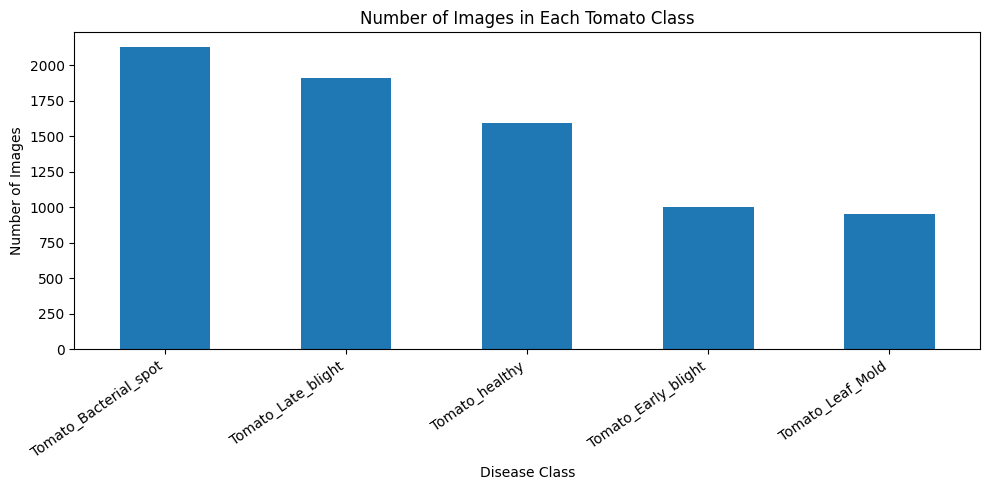

In [8]:
class_counts = df["class_name"].value_counts()

plt.figure(figsize=(10, 5))
class_counts.plot(kind="bar")
plt.title("Number of Images in Each Tomato Class")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Display sample images

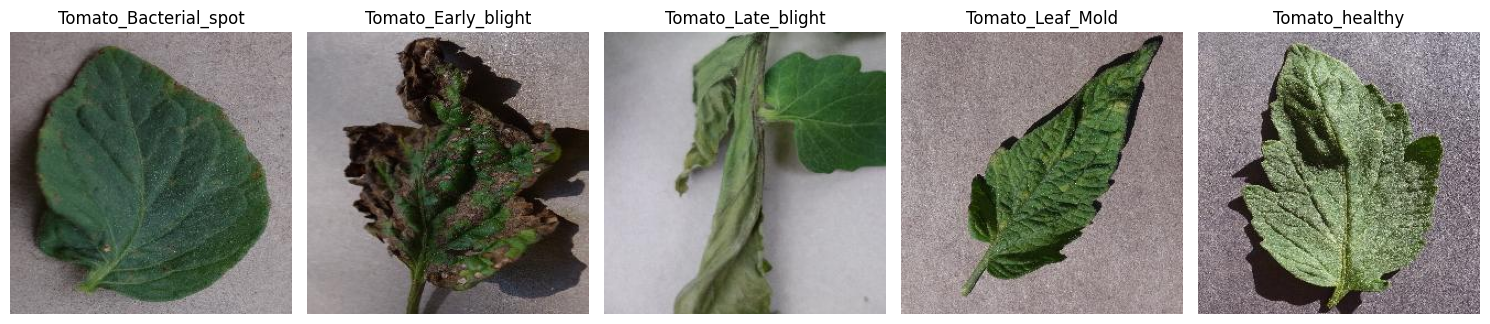

In [9]:
plt.figure(figsize=(15, 8))

for i, class_name in enumerate(CLASSES):
    samples = df[df["class_name"] == class_name]

    if len(samples) == 0:
        continue

    image_path = random.choice(samples["image_path"].tolist())
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(class_name.replace("Tomato___", ""))
    plt.axis("off")

plt.tight_layout()
plt.show()

### Check image dimensions

In [ ]:
dimensions = []

for image_path in df["image_path"]:
    image = cv2.imread(image_path)

    if image is not None:
        height, width, channels = image.shape
        dimensions.append((height, width, channels))

dimension_df = pd.DataFrame(
    dimensions,
    columns=["Height", "Width", "Channels"]
)

print(dimension_df.describe())
print("\nUnique image dimensions:")
print(dimension_df.drop_duplicates().head(10))

       Height   Width  Channels
count  7579.0  7579.0    7579.0
mean    256.0   256.0       3.0
std       0.0     0.0       0.0
min     256.0   256.0       3.0
25%     256.0   256.0       3.0
50%     256.0   256.0       3.0
75%     256.0   256.0       3.0
max     256.0   256.0       3.0

Unique image dimensions:
   Height  Width  Channels
0     256    256         3


### Save dataset metadata

In [12]:
df.to_csv(
    PROCESSED_PATH / "image_metadata.csv",
    index=False
)

print("Dataset metadata saved successfully.")

Dataset metadata saved successfully.
